In [1]:
import onnx
import onnxruntime
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from onnx_opcounter import calculate_params
import json
import glob
import os
from tqdm import tqdm

import sys
sys.path.append("../YOLOX")
from yolox.data.data_augment import preproc as preprocess
from yolox.data.datasets import COCO_CLASSES
from yolox.utils import mkdir, multiclass_nms, demo_postprocess, vis

sys.path.append("../../../drones/code/nn-shard-lite")
from src.utils.metricsevaluator import MetricsEvaluator

In [2]:
class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return json.JSONEncoder.default(self, obj)

In [3]:
score_thr = 0.1
# input_shape = 416, 416
input_shape = 192, 256

img_paths = [
    "../YOLOX/datasets/pg_coco/val2017/H265_test_office_2_20fps_N00019__9010.jpg",
    "../YOLOX/datasets/pg_coco/val2017/RegusPodil_H275_Cam3_meeting_5HO_STATIC_20fps_r1_20220202_142755__759.jpg",
    "../YOLOX/datasets/pg_coco/val2017/H265_Cam2_vayyar_init_subtraction_20fps_black_20211202_165234_N00021__60.jpg",
    "../YOLOX/datasets/pg_coco/test2017/H247_JCI_newtest_4_N00013__1839.jpg",
    "../YOLOX/datasets/pg_coco/test2017/BeeWorking_H245_Cam3_meeting_5HO_STATIC_20fps_r1_20220201_135602_10fps__1184.jpg"
    
]
session = onnxruntime.InferenceSession('../YOLOX_outputs/pg_coco_rgb_192/best_ckpt.onnx')

# origin_img = cv2.imread("../YOLOX/datasets/coco128/val2017/000000000005.jpg")
# origin_img = cv2.imread(
#     "../YOLOX/datasets/pg_coco/val2017/BeeWorking_H230_Cam3_meeting_5HO_STATIC_20fps_r1_20220201_120841_10fps__1030.jpg")

for img_path in img_paths:
    origin_img = cv2.imread(
        img_path)
    img, ratio = preprocess(origin_img, input_shape)


    ort_inputs = {session.get_inputs()[0].name: img[None, :, :, :]}
    output = session.run(None, ort_inputs)
    predictions = demo_postprocess(output[0], input_shape)[0]

    boxes = predictions[:, :4]
    scores = predictions[:, 4:5] * predictions[:, 5:]

    boxes_xyxy = np.ones_like(boxes)
    boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
    boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
    boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
    boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
    boxes_xyxy /= ratio
    dets = multiclass_nms(boxes_xyxy, scores, nms_thr=0.45, score_thr=0.11)
    break
    if dets is not None:
        final_boxes, final_scores, final_cls_inds = dets[:, :4], dets[:, 4], dets[:, 5]
        img = vis(origin_img.copy(), final_boxes, final_scores, final_cls_inds,
                         conf=score_thr, class_names=COCO_CLASSES)

    plt.figure(figsize=(25, 15))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(origin_img, cv2.COLOR_BGR2RGB))
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.tight_layout()

In [4]:
img.shape, ratio

((3, 192, 256), 0.4)

In [23]:
evaluator = MetricsEvaluator(
    is_relative_coordinates=False,
    is_xywh_coordinates=True,
)

In [24]:
with open("../YOLOX/datasets/pg_coco/annotations/instances_test.json", "rt") as f:
    test_data = json.load(f)

In [25]:
name_mapper = {}
id_mapper = {}
for i in test_data["images"]:
    name_mapper[i["file_name"]] = i["id"]
    id_mapper[i["id"]] = i["file_name"]

In [26]:
test_data["annotations"][0]

{'id': 1700000,
 'image_id': 170,
 'category_id': 0,
 'segmentation': [[398.0, 179.0, 126.0, 58.0]],
 'area': 7308.0,
 'bbox': [398.0, 179.0, 126.0, 58.0],
 'iscrowd': 0}

In [27]:
for annotation in test_data["annotations"]:
    evaluator.add_gt_box(
        img_path=annotation["image_id"],
        class_name=annotation["category_id"],
        bbox=annotation["bbox"]
    )


In [28]:
img_pths = sorted(glob.glob("../YOLOX/datasets/pg_coco/test2017/*.jpg"))

In [29]:
session = onnxruntime.InferenceSession('../YOLOX_outputs/pg_coco_rgb_192_no_mosaic/best_ckpt.onnx')

for img_pth in tqdm(img_pths):
    img_name = os.path.basename(img_pth)
    origin_img = cv2.imread(img_pth)
    img, ratio = preprocess(origin_img, input_shape)

    ort_inputs = {session.get_inputs()[0].name: img[None, :, :, :]}
    output = session.run(None, ort_inputs)
    predictions = demo_postprocess(output[0], input_shape)[0]

    boxes = predictions[:, :4]
    scores = predictions[:, 4:5] * predictions[:, 5:]

    boxes_xyxy = np.ones_like(boxes)
    boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
    boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
    boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
    boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
    boxes_xyxy /= ratio
    dets = multiclass_nms(boxes_xyxy, scores, nms_thr=0.65, score_thr=0.25)
    if dets is not None:
        final_boxes, final_scores, final_cls_inds = dets[:, :4], dets[:, 4], dets[:, 5]
        for det in dets:
            
            evaluator.add_det_box(
                img_path=name_mapper[img_name],
                class_name=det[5],
                bbox=[det[0], det[1], det[2] - det[0], det[3] - det[1]],
                confidence=det[4]
            )

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4558/4558 [00:50<00:00, 90.22it/s]


In [30]:
res = evaluator.eval_conf_vals(0.5, 1)

In [31]:
res = res[0]

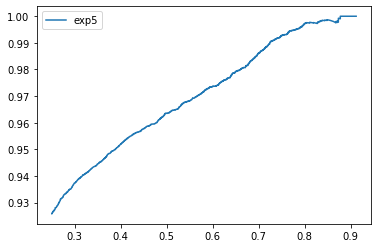

In [32]:
plt.plot(res["confidence"], res["precision"], label="exp5")
plt.legend()

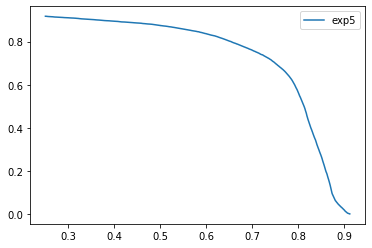

In [33]:
plt.plot(res["confidence"], res["recall"], label="exp5")
plt.legend()

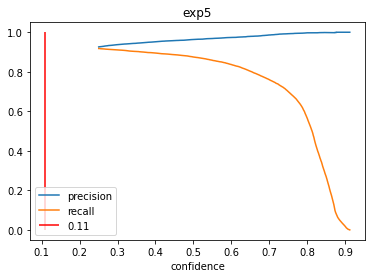

In [34]:
plt.plot(res["confidence"], res["precision"], label="precision")
plt.plot(res["confidence"], res["recall"], label="recall")
plt.title("exp5")
plt.vlines(0.11, 0, 1, label="0.11", colors="r")

plt.xlabel("confidence")
plt.legend()

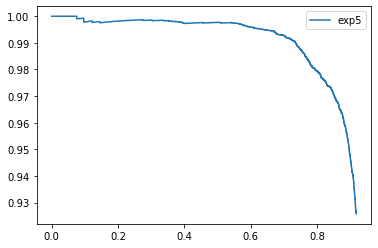

In [35]:
plt.plot(res["recall"], res["precision"], label="exp5")
plt.legend()

In [36]:
precision = res["total TP"] / (res["total TP"] + res["total FP"])
recall = res["total TP"] / (res["total positives"])

f_score = 2 * precision * recall / (precision + recall)

precision, recall, f_score

(0.9257638736964924, 0.9177329574206607, 0.9217309228200101)

Text(0.5, 1.0, 'exp5')

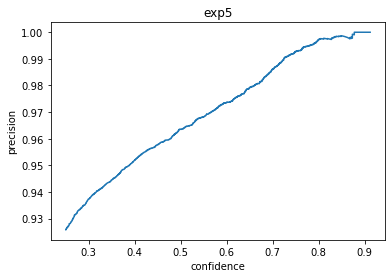

In [37]:
plt.plot(res["confidence"], res["precision"], label="exp5")
plt.xlabel("confidence")
plt.ylabel("precision")
plt.title("exp5")

Text(0.5, 1.0, 'exp5')

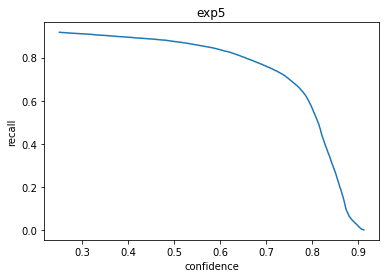

In [38]:
plt.plot(res["confidence"], res["recall"], label="exp5")
plt.xlabel("confidence")
plt.ylabel("recall")
plt.title("exp5")

Text(0.5, 1.0, 'exp5')

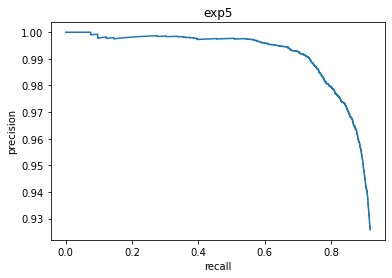

In [39]:
plt.plot(res["recall"], res["precision"], label="exp5")
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("exp5")

In [40]:
res["AP"]

0.9106651430634828